# CHB-MIT Continuous EEG-CASCADE and Bowen–Dinaburg Entropy Analysis

Continuous whole-recording performance and finite-time Bowen–Dinaburg entropy analysis across Rössler regimes, reservoir sizes, and reservoir realizations. CHB-MIT contains 24 case folders corresponding to 23 distinct individuals; `chb01` and `chb21` are mapped to one subject identity for subject-level inference.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)

RESULTS_ROOT = Path(
    "/data/halders2/EEG_anomaly/chbmit_continuous_BD_results"
)

ANALYSIS_OUT = Path(
    "/data/halders2/EEG_anomaly/chbmit_continuous_BD_analysis"
)
ANALYSIS_OUT.mkdir(parents=True, exist_ok=True)

PATIENTS = [f"chb{i:02d}" for i in range(1, 25)]
REGIMES = list(range(23))
N_VALUES = [5, 10, 20, 30, 40, 50]
SEEDS = [1107, 1249, 1388, 1523, 1697]
PERSISTENCE_SECONDS = 3.0
MIN_SUCCESSFUL_SEEDS = 4

print("Results root:", RESULTS_ROOT)
print("Analysis output:", ANALYSIS_OUT)


Results root: /data/halders2/EEG_anomaly/chbmit_continuous_BD_results
Analysis output: /data/halders2/EEG_anomaly/chbmit_continuous_BD_analysis


In [2]:
rows = []

for N in N_VALUES:
    for regime_id in REGIMES:
        for patient in PATIENTS:
            for seed in SEEDS:
                summary_file = (
                    RESULTS_ROOT
                    / f"N_{N}"
                    / f"regime_{regime_id}"
                    / patient
                    / f"seed_{seed}"
                    / "patient_continuous_summary.csv"
                )

                if not summary_file.exists():
                    continue

                try:
                    df = pd.read_csv(summary_file)
                except Exception as e:
                    print("Could not read:", summary_file, e)
                    continue

                if df.empty:
                    continue

                df = df[
                    np.isclose(
                        df["persistence_seconds"].astype(float),
                        PERSISTENCE_SECONDS
                    )
                ].copy()

                if df.empty:
                    continue

                for _, row in df.iterrows():
                    r = row.to_dict()
                    r["patient"] = patient
                    r["N"] = N
                    r["regime_id"] = regime_id
                    r["res_seed"] = seed
                    rows.append(r)

raw = pd.DataFrame(rows)

print("Successful run rows:", len(raw))
if len(raw):
    print("Patients found:", raw["patient"].nunique())
    print("Regimes found:", sorted(raw["regime_id"].unique()))
    print("N values found:", sorted(raw["N"].unique()))
    print("Seeds found:", sorted(raw["res_seed"].unique()))

display(raw.head())


Successful run rows: 16373
Patients found: 24
Regimes found: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22)]
N values found: [np.int64(5), np.int64(10), np.int64(20), np.int64(30), np.int64(40), np.int64(50)]
Seeds found: [np.int64(1107), np.int64(1249), np.int64(1388), np.int64(1523), np.int64(1697)]


,patient,analysis,data_seed,res_seed,regime_id,regime_name,num_reservoirs,pca_components,threshold_percentile,scalar_validation_threshold,rolling_steps,rolling_span_nominal_seconds,persistence_seconds,detection_window_seconds,n_total_edfs,n_development_edfs,n_continuous_test_edfs,n_test_seizure_edfs,n_test_seizure_free_edfs,train_scans,validation_scans,unused_sampled_dev_test_scans,n_seizures,n_detected_seizures,seizure_sensitivity,mean_detection_delay_seconds,median_detection_delay_seconds,clean_interictal_hours,interictal_false_alarm_episodes,false_alarms_per_hour,bd_entropy,bd_separated_count,bd_q,bd_epsilon,bd_steps,bd_finite_sample_bound,bd_saturated,bd_distance_min,bd_distance_q10,bd_distance_q25,bd_distance_median,bd_distance_q75,bd_distance_q90,bd_distance_max,projection_r_min,projection_r_max,z0_abs_mean,z0_abs_median,z0_abs_q90,z0_abs_q99,z0_abs_max,rossler_a_mean,rossler_a_std,rossler_b_mean,rossler_b_std,rossler_c_mean,rossler_c_std,tau_mean,tau_std,N
0,chb01,chbmit_patient_level_continuous_rolling30s,17,1107,0,low_complexity,5,30,5.0,-2587.007586,25,30.0,3.0,30.0,42,26,16,7,9,60,30,30,7,0,0.0,NaN,NaN,8.739722,8,0.915361,0.036620,3,64,0.05,30,0.138629,False,0.005448,0.014018,0.018033,0.023294,0.028965,0.035315,0.132667,-0.002483,0.002497,0.015472,0.012357,0.032452,0.059438,0.357861,0.106961,0.014399,0.101879,0.011709,2.036429,0.147295,1.310208,0.400923,5
1,chb01,chbmit_patient_level_continuous_rolling30s,17,1249,0,low_complexity,5,30,5.0,-2564.066530,25,30.0,3.0,30.0,42,26,16,7,9,60,30,30,7,0,0.0,NaN,NaN,8.739722,12,1.373041,0.036620,3,64,0.05,30,0.138629,False,0.003798,0.017288,0.022510,0.028686,0.035638,0.041713,0.059609,-0.002497,0.002491,0.017450,0.014200,0.035578,0.063858,0.307073,0.095883,0.010669,0.104926,0.010542,1.990756,0.078797,1.518955,0.254812,5
2,chb01,chbmit_patient_level_continuous_rolling30s,17,1388,0,low_complexity,5,30,5.0,-2640.355254,25,30.0,3.0,30.0,42,26,16,7,9,60,30,30,7,0,0.0,NaN,NaN,8.739722,8,0.915361,0.023105,2,64,0.05,30,0.138629,False,0.002712,0.016009,0.021388,0.027172,0.034111,0.040793,0.065763,-0.002497,0.002468,0.016819,0.013772,0.034138,0.063502,0.342380,0.098954,0.012402,0.103786,0.014514,2.029318,0.105316,1.319107,0.306672,5
3,chb01,chbmit_patient_level_continuous_rolling30s,17,1523,0,low_complexity,5,30,5.0,-2515.919390,25,30.0,3.0,30.0,42,26,16,7,9,60,30,30,7,0,0.0,NaN,NaN,8.739722,11,1.258621,0.023105,2,64,0.05,30,0.138629,False,0.004048,0.016202,0.021351,0.027838,0.035578,0.043106,0.056774,-0.002479,0.002492,0.017572,0.013888,0.037317,0.066786,0.282433,0.097470,0.005369,0.096960,0.010547,1.979181,0.097687,1.589502,0.136486,5
4,chb01,chbmit_patient_level_continuous_rolling30s,17,1697,0,low_complexity,5,30,5.0,-2541.770250,25,30.0,3.0,30.0,42,26,16,7,9,60,30,30,7,0,0.0,NaN,NaN,8.739722,12,1.373041,0.036620,3,64,0.05,30,0.138629,False,0.004392,0.014717,0.019437,0.025792,0.031655,0.040008,0.170211,-0.002479,0.002488,0.015615,0.012705,0.031745,0.058955,0.290814,0.100263,0.016858,0.100453,0.009204,2.009845,0.137661,1.780731,0.237316,5


In [3]:
bd_cols = [
    c for c in raw.columns
    if c.startswith("bd_") or c.startswith("rossler_") or c.startswith("tau_")
]

print("BD / dynamical columns:")
for c in bd_cols:
    print(c)

required = [
    "patient", "N", "regime_id", "res_seed",
    "bd_entropy", "bd_separated_count", "bd_q", "bd_epsilon",
    "bd_steps", "bd_saturated",
    "seizure_sensitivity", "false_alarms_per_hour",
    "mean_detection_delay_seconds", "clean_interictal_hours",
]

missing = [c for c in required if c not in raw.columns]
if missing:
    raise RuntimeError(f"Missing required columns: {missing}")

print("All required columns are present.")


BD / dynamical columns:
bd_entropy
bd_separated_count
bd_q
bd_epsilon
bd_steps
bd_finite_sample_bound
bd_saturated
bd_distance_min
bd_distance_q10
bd_distance_q25
bd_distance_median
bd_distance_q75
bd_distance_q90
bd_distance_max
rossler_a_mean
rossler_a_std
rossler_b_mean
rossler_b_std
rossler_c_mean
rossler_c_std
tau_mean
tau_std
All required columns are present.


## Subject identity and configuration stability


In [4]:
def case_to_subject(case):
    if case in {"chb01", "chb21"}:
        return "subject_chb01_chb21"
    return f"subject_{case}"

raw["subject_id"] = raw["patient"].map(case_to_subject)

print("Number of case folders:", raw["patient"].nunique())
print("Number of distinct individuals:", raw["subject_id"].nunique())

display(
    raw.loc[
        raw["patient"].isin(["chb01", "chb21"]),
        ["patient", "subject_id"]
    ].drop_duplicates().sort_values("patient")
)


Number of case folders: 24
Number of distinct individuals: 23


,patient,subject_id
0,chb01,subject_chb01_chb21
97,chb21,subject_chb01_chb21


In [5]:
seed_counts = (
    raw.groupby(["patient", "N", "regime_id"], as_index=False)
    .agg(successful_seeds=("res_seed", "nunique"))
)

display(
    seed_counts["successful_seeds"]
    .value_counts()
    .sort_index()
    .rename_axis("successful_seeds")
    .to_frame("n_configurations")
)

stable_configs = seed_counts[
    seed_counts["successful_seeds"] >= MIN_SUCCESSFUL_SEEDS
].copy()

print(f"Stable configurations (>={MIN_SUCCESSFUL_SEEDS}/5 seeds):", len(stable_configs))


,n_configurations
successful_seeds,
1,5
2,9
3,9
4,22
5,3247


Stable configurations (>=4/5 seeds): 3269


In [6]:
stable_raw = raw.merge(
    stable_configs[["patient", "N", "regime_id"]],
    on=["patient", "N", "regime_id"],
    how="inner"
)
print("Seed-level rows in stable configurations:", len(stable_raw))


Seed-level rows in stable configurations: 16323


In [7]:
sat = stable_raw["bd_saturated"].copy()
if sat.dtype == object:
    sat = sat.astype(str).str.lower().map({
        "true": True, "false": False, "1": True, "0": False
    })

stable_raw["bd_saturated_bool"] = sat

print("BD saturation counts:")
display(stable_raw["bd_saturated_bool"].value_counts(dropna=False).to_frame("n_runs"))
print("Saturated runs:", int(stable_raw["bd_saturated_bool"].fillna(False).sum()), "/", len(stable_raw))


BD saturation counts:


,n_runs
bd_saturated_bool,
False,16323


Saturated runs: 0 / 16323


In [8]:
agg_map = {
    "successful_seeds": ("res_seed", "nunique"),
    "bd_entropy_mean": ("bd_entropy", "mean"),
    "bd_entropy_sd": ("bd_entropy", "std"),
    "sensitivity_mean": ("seizure_sensitivity", "mean"),
    "sensitivity_sd": ("seizure_sensitivity", "std"),
    "far_mean": ("false_alarms_per_hour", "mean"),
    "far_sd": ("false_alarms_per_hour", "std"),
    "delay_mean": ("mean_detection_delay_seconds", "mean"),
    "delay_sd": ("mean_detection_delay_seconds", "std"),
    "clean_hours_mean": ("clean_interictal_hours", "mean"),
}

if "n_seizures" in stable_raw.columns:
    agg_map["n_seizures"] = ("n_seizures", "first")

patient_config = (
    stable_raw
    .groupby(["patient", "subject_id", "N", "regime_id"], as_index=False)
    .agg(**agg_map)
)

display(patient_config.head())

patient_config.to_csv(
    ANALYSIS_OUT / "case_level_configurations_24_cases.csv",
    index=False
)


,patient,subject_id,N,regime_id,successful_seeds,bd_entropy_mean,bd_entropy_sd,sensitivity_mean,sensitivity_sd,far_mean,far_sd,delay_mean,delay_sd,clean_hours_mean,n_seizures
0,chb01,subject_chb01_chb21,5,0,5,0.031214,0.007403,0.0,0.0,1.167085,0.234491,NaN,NaN,8.739722,7
1,chb01,subject_chb01_chb21,5,1,5,0.031214,0.007403,0.0,0.0,1.098433,0.223046,NaN,NaN,8.739722,7
2,chb01,subject_chb01_chb21,5,2,5,0.028511,0.007403,0.0,0.0,1.098433,0.223046,NaN,NaN,8.739722,7
3,chb01,subject_chb01_chb21,5,3,5,0.028511,0.007403,0.0,0.0,1.121317,0.248057,NaN,NaN,8.739722,7
4,chb01,subject_chb01_chb21,5,4,5,0.028511,0.007403,0.0,0.0,1.121317,0.248057,NaN,NaN,8.739722,7


In [9]:
cohort_case = (
    patient_config
    .groupby(["N", "regime_id"], as_index=False)
    .agg(
        n_cases=("patient", "nunique"),
        bd_entropy_mean=("bd_entropy_mean", "mean"),
        bd_entropy_sd=("bd_entropy_mean", "std"),
        sensitivity_mean=("sensitivity_mean", "mean"),
        sensitivity_sd=("sensitivity_mean", "std"),
        far_mean=("far_mean", "mean"),
        far_sd=("far_mean", "std"),
        delay_mean=("delay_mean", "mean"),
        delay_sd=("delay_mean", "std"),
    )
)
display(cohort_case.head())


,N,regime_id,n_cases,bd_entropy_mean,bd_entropy_sd,sensitivity_mean,sensitivity_sd,far_mean,far_sd,delay_mean,delay_sd
0,5,0,23,0.034280,0.004209,0.519234,0.395622,10.566750,6.709299,15.073006,5.715092
1,5,1,24,0.034120,0.004244,0.519335,0.384169,10.327804,6.599823,15.222441,5.654369
2,5,2,24,0.034172,0.004312,0.520585,0.382246,10.292653,6.580498,14.984169,5.556770
3,5,3,24,0.033722,0.004432,0.522530,0.383245,10.308187,6.597302,14.264653,4.561535
4,5,4,24,0.033191,0.004243,0.520863,0.381342,10.288498,6.610828,14.231178,4.608768


## Subject-level pooling


In [10]:
needed_pool_cols = {
    "n_seizures", "n_detected_seizures",
    "interictal_false_alarm_episodes", "clean_interictal_hours"
}

can_exact_pool = needed_pool_cols.issubset(stable_raw.columns)
print("Exact event/hour pooling available:", can_exact_pool)

seed_subject_rows = []

for (subject_id, N, regime_id, seed), g in stable_raw.groupby(
    ["subject_id", "N", "regime_id", "res_seed"]
):
    if can_exact_pool:
        total_seizures = g["n_seizures"].sum()
        total_detected = g["n_detected_seizures"].sum()
        sensitivity = total_detected / total_seizures if total_seizures > 0 else np.nan

        total_hours = g["clean_interictal_hours"].sum()
        total_false_alarms = g["interictal_false_alarm_episodes"].sum()
        far = total_false_alarms / total_hours if total_hours > 0 else np.nan
    else:
        total_seizures = np.nan
        total_detected = np.nan
        total_hours = g["clean_interictal_hours"].sum()
        total_false_alarms = np.nan
        sensitivity = g["seizure_sensitivity"].mean()
        far = g["false_alarms_per_hour"].mean()

    bd_entropy = g["bd_entropy"].mean()

    delay_valid = g[
        g["mean_detection_delay_seconds"].notna()
    ].copy()

    if len(delay_valid) and "n_detected_seizures" in delay_valid.columns and (delay_valid["n_detected_seizures"] > 0).any():
        d2 = delay_valid[delay_valid["n_detected_seizures"] > 0]
        delay = np.average(
            d2["mean_detection_delay_seconds"],
            weights=d2["n_detected_seizures"]
        )
    elif len(delay_valid):
        delay = delay_valid["mean_detection_delay_seconds"].mean()
    else:
        delay = np.nan

    seed_subject_rows.append({
        "subject_id": subject_id,
        "N": N,
        "regime_id": regime_id,
        "res_seed": seed,
        "n_case_folders": g["patient"].nunique(),
        "bd_entropy": bd_entropy,
        "n_seizures": total_seizures,
        "n_detected_seizures": total_detected,
        "seizure_sensitivity": sensitivity,
        "clean_interictal_hours": total_hours,
        "interictal_false_alarm_episodes": total_false_alarms,
        "false_alarms_per_hour": far,
        "mean_detection_delay_seconds": delay,
    })

subject_seed = pd.DataFrame(seed_subject_rows)
print("Distinct subjects:", subject_seed["subject_id"].nunique())
display(subject_seed.head())


Exact event/hour pooling available: True
Distinct subjects: 23


,subject_id,N,regime_id,res_seed,n_case_folders,bd_entropy,n_seizures,n_detected_seizures,seizure_sensitivity,clean_interictal_hours,interictal_false_alarm_episodes,false_alarms_per_hour,mean_detection_delay_seconds
0,subject_chb01_chb21,5,0,1107,2,0.029863,11,0,0.000000,15.739444,63,4.002683,NaN
1,subject_chb01_chb21,5,0,1249,2,0.041415,11,0,0.000000,15.739444,67,4.256821,NaN
2,subject_chb01_chb21,5,0,1388,2,0.029863,11,2,0.181818,15.739444,63,4.002683,18.0
3,subject_chb01_chb21,5,0,1523,2,0.034657,11,0,0.000000,15.739444,73,4.638029,NaN
4,subject_chb01_chb21,5,0,1697,2,0.036620,11,2,0.181818,15.739444,71,4.510960,28.5


In [11]:
subject_config_pooled = (
    subject_seed
    .groupby(["subject_id", "N", "regime_id"], as_index=False)
    .agg(
        successful_seeds=("res_seed", "nunique"),
        bd_entropy_mean=("bd_entropy", "mean"),
        bd_entropy_sd=("bd_entropy", "std"),
        sensitivity_mean=("seizure_sensitivity", "mean"),
        sensitivity_sd=("seizure_sensitivity", "std"),
        far_mean=("false_alarms_per_hour", "mean"),
        far_sd=("false_alarms_per_hour", "std"),
        delay_mean=("mean_detection_delay_seconds", "mean"),
        delay_sd=("mean_detection_delay_seconds", "std"),
    )
)

subject_config_pooled = subject_config_pooled[
    subject_config_pooled["successful_seeds"] >= MIN_SUCCESSFUL_SEEDS
].copy()

print("Number of distinct subjects:", subject_config_pooled["subject_id"].nunique())
subject_config_pooled.to_csv(
    ANALYSIS_OUT / "subject_level_configurations_23_individuals.csv",
    index=False
)
display(subject_config_pooled.head())


Number of distinct subjects: 23


,subject_id,N,regime_id,successful_seeds,bd_entropy_mean,bd_entropy_sd,sensitivity_mean,sensitivity_sd,far_mean,far_sd,delay_mean,delay_sd
0,subject_chb01_chb21,5,0,5,0.034484,0.004882,0.072727,0.099586,4.282235,0.289763,23.25,7.424621
1,subject_chb01_chb21,5,1,5,0.034484,0.004882,0.072727,0.099586,4.269528,0.400319,23.00,7.778175
2,subject_chb01_chb21,5,2,5,0.030822,0.005238,0.090909,0.128565,4.345770,0.468177,18.25,1.060660
3,subject_chb01_chb21,5,3,5,0.029863,0.004778,0.090909,0.128565,4.371184,0.488845,18.00,1.414214
4,subject_chb01_chb21,5,4,5,0.029863,0.004778,0.090909,0.128565,4.383890,0.433249,18.00,1.414214


## Illustrative subject-level BD–performance relationships


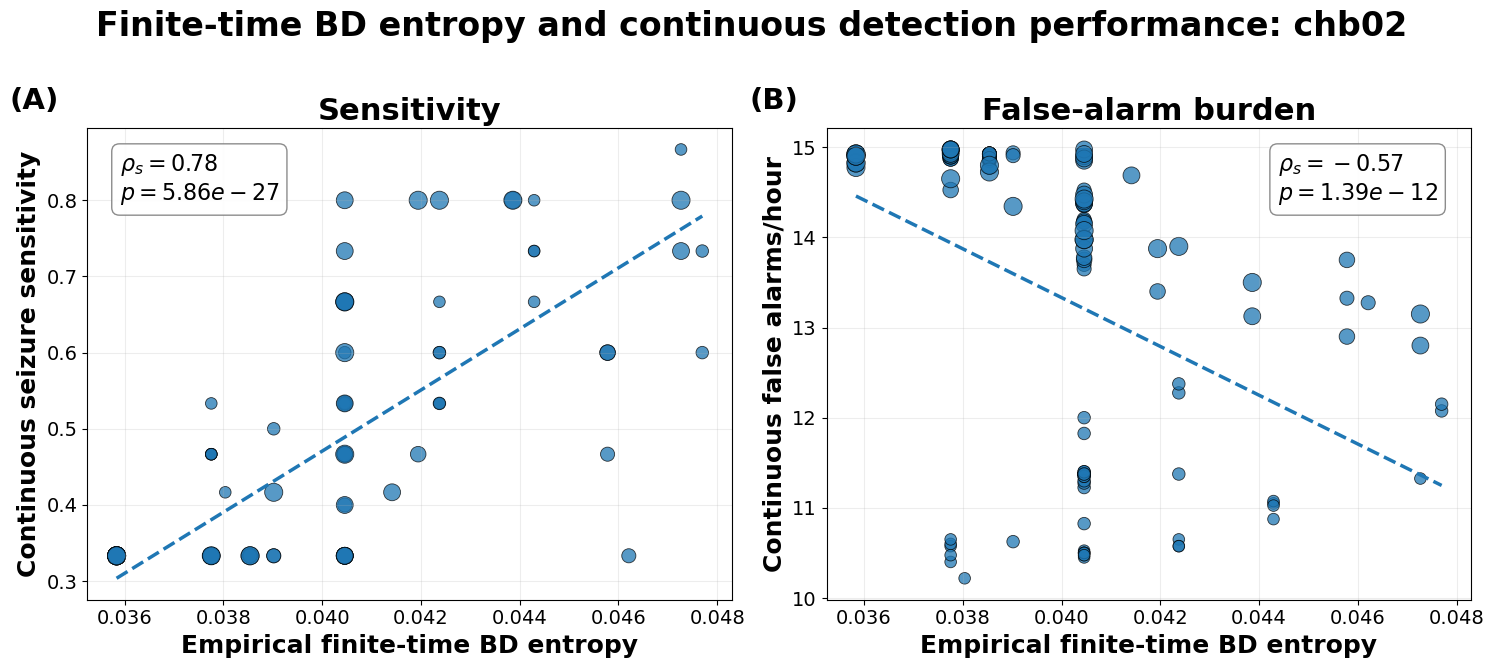

In [12]:
# ============================================================
# Illustrative subject: BD entropy and continuous performance
# Two-panel manuscript figure
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

ILLUSTRATIVE_SUBJECT = "subject_chb02"

patient_df = (
    subject_config_pooled[
        subject_config_pooled["subject_id"] == ILLUSTRATIVE_SUBJECT
    ]
    .dropna(
        subset=[
            "bd_entropy_mean",
            "sensitivity_mean",
            "far_mean",
            "N",
        ]
    )
    .copy()
)

if len(patient_df) < 4:
    raise RuntimeError(
        f"Too few valid configurations for {ILLUSTRATIVE_SUBJECT}"
    )

rho_sens, p_sens = spearmanr(
    patient_df["bd_entropy_mean"],
    patient_df["sensitivity_mean"],
)

rho_far, p_far = spearmanr(
    patient_df["bd_entropy_mean"],
    patient_df["far_mean"],
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6.5),
)

# Marker size encodes reservoir count N
N_min = patient_df["N"].min()
N_max = patient_df["N"].max()

if N_max > N_min:
    marker_sizes = 70 + 100 * (
        (patient_df["N"] - N_min) / (N_max - N_min)
    )
else:
    marker_sizes = np.full(len(patient_df), 100)

# ============================================================
# Panel A: sensitivity
# ============================================================

ax = axes[0]

x = patient_df["bd_entropy_mean"].to_numpy()
y = patient_df["sensitivity_mean"].to_numpy()

ax.scatter(
    x,
    y,
    s=marker_sizes,
    alpha=0.75,
    edgecolor="black",
    linewidth=0.6,
)

# Linear visual guide
if np.unique(x).size > 1:
    coef = np.polyfit(x, y, 1)
    xx = np.linspace(x.min(), x.max(), 200)
    yy = np.polyval(coef, xx)

    ax.plot(
        xx,
        yy,
        linewidth=2.5,
        linestyle="--",
        label="Linear visual guide",
    )

ax.set_xlabel(
    "Empirical finite-time BD entropy",
    fontsize=18,
    fontweight="bold",
)

ax.set_ylabel(
    "Continuous seizure sensitivity",
    fontsize=18,
    fontweight="bold",
)

ax.set_title(
    "Sensitivity",
    fontsize=22,
    fontweight="bold",
)

ax.text(
    0.05,
    0.95,
    rf"$\rho_s = {rho_sens:.2f}$"
    + "\n"
    + rf"$p = {p_sens:.2e}$",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=16,
    fontweight="bold",
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        alpha=0.9,
        edgecolor="0.5",
    ),
)

ax.text(
    -0.12,
    1.04,
    "(A)",
    transform=ax.transAxes,
    fontsize=21,
    fontweight="bold",
)

ax.tick_params(
    axis="both",
    labelsize=14,
)

ax.grid(
    alpha=0.22,
)

# ============================================================
# Panel B: false alarms/hour
# ============================================================

ax = axes[1]

x = patient_df["bd_entropy_mean"].to_numpy()
y = patient_df["far_mean"].to_numpy()

ax.scatter(
    x,
    y,
    s=marker_sizes,
    alpha=0.75,
    edgecolor="black",
    linewidth=0.6,
)

# Linear visual guide
if np.unique(x).size > 1:
    coef = np.polyfit(x, y, 1)
    xx = np.linspace(x.min(), x.max(), 200)
    yy = np.polyval(coef, xx)

    ax.plot(
        xx,
        yy,
        linewidth=2.5,
        linestyle="--",
        label="Linear visual guide",
    )

ax.set_xlabel(
    "Empirical finite-time BD entropy",
    fontsize=18,
    fontweight="bold",
)

ax.set_ylabel(
    "Continuous false alarms/hour",
    fontsize=18,
    fontweight="bold",
)

ax.set_title(
    "False-alarm burden",
    fontsize=22,
    fontweight="bold",
)

ax.text(
    0.70,
    0.95,
    rf"$\rho_s = {rho_far:.2f}$"
    + "\n"
    + rf"$p = {p_far:.2e}$",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=16,
    fontweight="bold",
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        alpha=0.9,
        edgecolor="0.5",
    ),
)

ax.text(
    -0.12,
    1.04,
    "(B)",
    transform=ax.transAxes,
    fontsize=21,
    fontweight="bold",
)

ax.tick_params(
    axis="both",
    labelsize=14,
)

ax.grid(
    alpha=0.22,
)

# ============================================================
# Shared title
# ============================================================

fig.suptitle(
    f"Finite-time BD entropy and continuous detection performance: "
    f"{ILLUSTRATIVE_SUBJECT.replace('subject_', '')}",
    fontsize=24,
    fontweight="bold",
    y=1.02,
)

plt.tight_layout()

plt.savefig(
    ANALYSIS_OUT
    / f"{ILLUSTRATIVE_SUBJECT}_BD_continuous_performance_clean.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Population-level BD–performance associations


In [13]:
# ============================================================
# Population-level within-subject BD-performance associations
#
# Favorable directions:
#   Sensitivity       -> rho > 0
#   False alarms/hour -> rho < 0
#   Detection delay   -> rho < 0
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, wilcoxon

# ------------------------------------------------------------
# 1. Compute within-subject Spearman correlations
# ------------------------------------------------------------

metric_defs = {
    "Sensitivity": "sensitivity_mean",
    "False alarms/hour": "far_mean",
    "Detection delay": "delay_mean",
}

corr_rows = []

for subject_id, g in subject_config_pooled.groupby("subject_id"):

    for metric_name, metric_col in metric_defs.items():

        d = g[
            ["bd_entropy_mean", metric_col]
        ].dropna().copy()

        # Need enough valid configurations
        if len(d) < 4:
            continue

        # Correlation undefined if either variable is constant
        if d["bd_entropy_mean"].nunique() < 2:
            continue

        if d[metric_col].nunique() < 2:
            continue

        rho, p = spearmanr(
            d["bd_entropy_mean"],
            d[metric_col],
        )

        corr_rows.append({
            "subject_id": subject_id,
            "metric": metric_name,
            "n_configurations": len(d),
            "rho": rho,
            "p_within_subject": p,
        })

within_corr = pd.DataFrame(corr_rows)

print("Number of distinct subjects contributing:")
display(
    within_corr.groupby("metric")["subject_id"]
    .nunique()
    .to_frame("n_subjects")
)

display(within_corr.head())

Number of distinct subjects contributing:


,n_subjects
metric,
Detection delay,21
False alarms/hour,23
Sensitivity,21


,subject_id,metric,n_configurations,rho,p_within_subject
0,subject_chb01_chb21,Sensitivity,138,0.260898,1.996939e-03
1,subject_chb01_chb21,False alarms/hour,138,-0.303473,2.965639e-04
2,subject_chb01_chb21,Detection delay,64,-0.377442,2.107780e-03
3,subject_chb02,Sensitivity,128,0.775734,5.860016e-27
4,subject_chb02,False alarms/hour,128,-0.574129,1.390930e-12


In [14]:
# ------------------------------------------------------------
# 2. Population summary across independent subjects
# ------------------------------------------------------------

summary_rows = []

for metric_name in metric_defs:

    vals = (
        within_corr.loc[
            within_corr["metric"] == metric_name,
            "rho"
        ]
        .dropna()
        .to_numpy()
    )

    n = len(vals)

    if n == 0:
        continue

    median_rho = np.median(vals)
    q25 = np.quantile(vals, 0.25)
    q75 = np.quantile(vals, 0.75)

    n_positive = np.sum(vals > 0)
    n_negative = np.sum(vals < 0)
    n_zero = np.sum(vals == 0)

    # Two-sided Wilcoxon signed-rank test against zero
    # This tests whether the distribution of within-subject
    # correlations is centered away from zero.
    try:
        w_stat, w_p = wilcoxon(
            vals,
            alternative="two-sided",
            zero_method="wilcox",
        )
    except ValueError:
        w_stat, w_p = np.nan, np.nan

    # Favorable-direction count
    if metric_name == "Sensitivity":
        n_favorable = np.sum(vals > 0)
    else:
        n_favorable = np.sum(vals < 0)

    summary_rows.append({
        "metric": metric_name,
        "n_subjects": n,
        "median_rho": median_rho,
        "q25": q25,
        "q75": q75,
        "n_positive": n_positive,
        "n_negative": n_negative,
        "n_zero": n_zero,
        "n_favorable": n_favorable,
        "favorable_fraction": n_favorable / n,
        "wilcoxon_stat": w_stat,
        "wilcoxon_p": w_p,
    })

corr_summary = pd.DataFrame(summary_rows)

display(corr_summary)

,metric,n_subjects,median_rho,q25,q75,n_positive,n_negative,n_zero,n_favorable,favorable_fraction,wilcoxon_stat,wilcoxon_p
0,Sensitivity,21,0.123431,0.019531,0.374574,16,5,0,16,0.761905,58.0,0.045993
1,False alarms/hour,23,-0.269706,-0.450188,-0.075532,5,18,0,18,0.782609,47.0,0.004339
2,Detection delay,21,-0.104318,-0.377442,0.155545,8,13,0,13,0.619048,83.0,0.272210


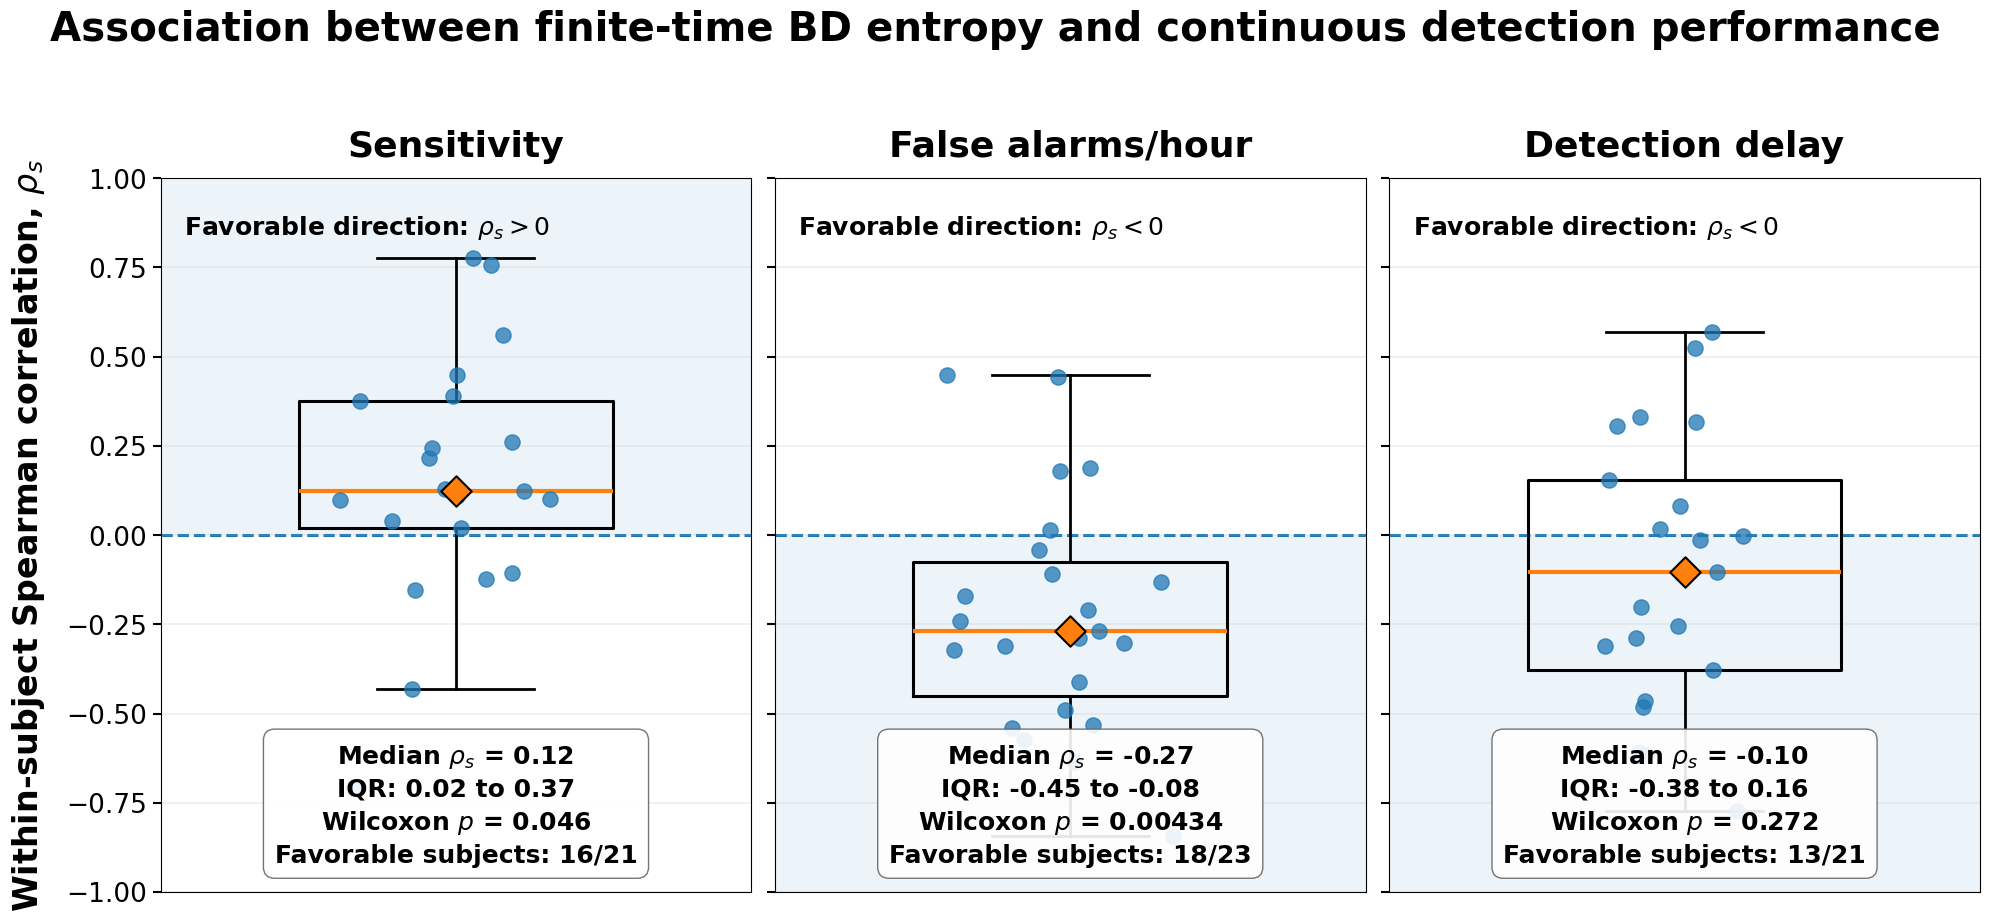

In [15]:
# ============================================================
# Boxplot + individual subjects + favorable region
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

plot_order = [
    "Sensitivity",
    "False alarms/hour",
    "Detection delay",
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(20, 9),
    sharey=True,
)

rng = np.random.default_rng(17)

for ax, metric in zip(axes, plot_order):

    vals = (
        within_corr.loc[
            within_corr["metric"] == metric,
            "rho"
        ]
        .dropna()
        .to_numpy()
    )

    row = corr_summary[
        corr_summary["metric"] == metric
    ].iloc[0]

    median_rho = row["median_rho"]
    q25 = row["q25"]
    q75 = row["q75"]
    pval = row["wilcoxon_p"]
    n_fav = int(row["n_favorable"])
    n_sub = int(row["n_subjects"])

    # --------------------------------------------------------
    # Favorable region
    # --------------------------------------------------------

    if metric == "Sensitivity":
        ax.axhspan(
            0, 1,
            alpha=0.08,
        )
        favorable_text = r"Favorable direction: $\rho_s > 0$"

    else:
        ax.axhspan(
            -1, 0,
            alpha=0.08,
        )
        favorable_text = r"Favorable direction: $\rho_s < 0$"

    # --------------------------------------------------------
    # Zero-reference line
    # --------------------------------------------------------

    ax.axhline(
        0,
        linestyle="--",
        linewidth=2.2,
        zorder=1,
    )

    # --------------------------------------------------------
    # Boxplot
    # --------------------------------------------------------

    ax.boxplot(
        vals,
        positions=[1],
        widths=0.34,
        vert=True,
        showfliers=False,
        patch_artist=False,
        medianprops={
            "linewidth": 3.0,
        },
        boxprops={
            "linewidth": 2.2,
        },
        whiskerprops={
            "linewidth": 2.0,
        },
        capprops={
            "linewidth": 2.0,
        },
    )

    # --------------------------------------------------------
    # Individual subject points
    # --------------------------------------------------------

    jitter = rng.normal(
        loc=0,
        scale=0.055,
        size=len(vals),
    )

    ax.scatter(
        np.full(len(vals), 1) + jitter,
        vals,
        s=120,
        alpha=0.75,
        zorder=3,
    )

    # --------------------------------------------------------
    # Median marker
    # --------------------------------------------------------

    ax.scatter(
        1,
        median_rho,
        s=240,
        marker="D",
        edgecolor="black",
        linewidth=1.5,
        zorder=5,
    )

    # --------------------------------------------------------
    # Panel title
    # --------------------------------------------------------

    ax.set_title(
        metric,
        fontsize=26,
        fontweight="bold",
        pad=16,
    )

    # --------------------------------------------------------
    # Favorable-direction annotation
    # --------------------------------------------------------

    ax.text(
        0.04,
        0.95,
        favorable_text,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=18,
        fontweight="bold",
    )

    # --------------------------------------------------------
    # Statistical annotation
    # --------------------------------------------------------

    stats_text = (
        rf"Median $\rho_s$ = {median_rho:.2f}"
        "\n"
        rf"IQR: {q25:.2f} to {q75:.2f}"
        "\n"
        rf"Wilcoxon $p$ = {pval:.3g}"
        "\n"
        f"Favorable subjects: {n_fav}/{n_sub}"
    )

    ax.text(
        0.50,
        0.035,
        stats_text,
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=18,
        fontweight="bold",
        linespacing=1.35,
        bbox=dict(
            boxstyle="round,pad=0.45",
            facecolor="white",
            alpha=0.90,
            edgecolor="0.4",
            linewidth=1.0,
        ),
    )

    # --------------------------------------------------------
    # Axes formatting
    # --------------------------------------------------------

    ax.set_xlim(0.68, 1.32)
    ax.set_ylim(-1.0, 1.0)

    ax.set_xticks([])

    ax.tick_params(
        axis="y",
        labelsize=19,
        width=1.5,
        length=6,
    )

    ax.grid(
        axis="y",
        alpha=0.22,
        linewidth=1.1,
    )

# ------------------------------------------------------------
# Shared y-axis label
# ------------------------------------------------------------

axes[0].set_ylabel(
    r"Within-subject Spearman correlation, $\rho_s$",
    fontsize=24,
    fontweight="bold",
    labelpad=14,
)

# ------------------------------------------------------------
# Main figure title
# ------------------------------------------------------------

fig.suptitle(
    "Association between finite-time BD entropy and continuous detection performance",
    fontsize=29,
    fontweight="bold",
    y=1.015,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.savefig(
    ANALYSIS_OUT /
    "BD_population_boxplot_subjects_final_large_text.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Fixed-reservoir-size sensitivity analysis


In [16]:
# ============================================================
#
# Within each fixed reservoir size N:
#   correlate BD entropy with performance across regimes
#
# This determines whether the BD-performance association
# persists when reservoir dimensionality is held constant.
# ============================================================

from scipy.stats import spearmanr, wilcoxon
import numpy as np
import pandas as pd

metric_defs = {
    "Sensitivity": "sensitivity_mean",
    "False alarms/hour": "far_mean",
    "Detection delay": "delay_mean",
}

fixedN_rows = []

for N in N_VALUES:

    dN = subject_config_pooled[
        subject_config_pooled["N"] == N
    ].copy()

    for subject_id, g in dN.groupby("subject_id"):

        for metric_name, metric_col in metric_defs.items():

            d = g[
                ["regime_id", "bd_entropy_mean", metric_col]
            ].dropna().copy()

            # Need enough regimes to estimate a meaningful correlation
            if len(d) < 4:
                continue

            if d["bd_entropy_mean"].nunique() < 2:
                continue

            if d[metric_col].nunique() < 2:
                continue

            rho, p = spearmanr(
                d["bd_entropy_mean"],
                d[metric_col],
            )

            fixedN_rows.append({
                "N": N,
                "subject_id": subject_id,
                "metric": metric_name,
                "n_regimes": len(d),
                "rho": rho,
                "p_within_subject": p,
            })

fixedN_corr = pd.DataFrame(fixedN_rows)

display(fixedN_corr.head())

,N,subject_id,metric,n_regimes,rho,p_within_subject
0,5,subject_chb01_chb21,Sensitivity,23,0.176775,4.197306e-01
1,5,subject_chb01_chb21,False alarms/hour,23,-0.417615,4.739065e-02
2,5,subject_chb01_chb21,Detection delay,23,-0.157992,4.715301e-01
3,5,subject_chb02,Sensitivity,22,0.906280,6.378628e-09
4,5,subject_chb02,False alarms/hour,22,0.640506,1.321706e-03


In [17]:
# ============================================================
# Population summary at each fixed N
# ============================================================

fixedN_summary_rows = []

for N in N_VALUES:

    for metric_name in metric_defs:

        vals = (
            fixedN_corr.loc[
                (fixedN_corr["N"] == N)
                & (fixedN_corr["metric"] == metric_name),
                "rho"
            ]
            .dropna()
            .to_numpy()
        )

        if len(vals) == 0:
            continue

        median_rho = np.median(vals)
        q25 = np.quantile(vals, 0.25)
        q75 = np.quantile(vals, 0.75)

        if metric_name == "Sensitivity":
            n_favorable = np.sum(vals > 0)
        else:
            n_favorable = np.sum(vals < 0)

        try:
            W, p_wilcoxon = wilcoxon(
                vals,
                alternative="two-sided",
                zero_method="wilcox",
            )
        except ValueError:
            W, p_wilcoxon = np.nan, np.nan

        fixedN_summary_rows.append({
            "N": N,
            "metric": metric_name,
            "n_subjects": len(vals),
            "median_rho": median_rho,
            "q25": q25,
            "q75": q75,
            "n_favorable": n_favorable,
            "favorable_fraction": n_favorable / len(vals),
            "wilcoxon_stat": W,
            "wilcoxon_p": p_wilcoxon,
        })

fixedN_summary = pd.DataFrame(fixedN_summary_rows)

display(
    fixedN_summary.sort_values(
        ["metric", "N"]
    )
)

,N,metric,n_subjects,median_rho,q25,q75,n_favorable,favorable_fraction,wilcoxon_stat,wilcoxon_p
2,5,Detection delay,19,-0.471935,-0.667923,0.061536,13,0.684211,42.0,0.032341
5,10,Detection delay,21,-0.143925,-0.561368,0.442323,12,0.571429,111.0,0.891732
8,20,Detection delay,19,-0.278876,-0.515744,0.201498,11,0.578947,69.0,0.312408
11,30,Detection delay,20,-0.067562,-0.618559,0.419038,11,0.550000,91.0,0.621513
14,40,Detection delay,19,-0.229416,-0.804136,0.573611,11,0.578947,71.0,0.352459
17,50,Detection delay,19,-0.463276,-0.760042,0.456254,12,0.631579,53.0,0.095512
1,5,False alarms/hour,23,0.093068,-0.290268,0.439226,9,0.391304,113.0,0.463381
4,10,False alarms/hour,23,-0.179760,-0.340132,0.345081,15,0.652174,112.0,0.445200
7,20,False alarms/hour,23,-0.687529,-0.782130,-0.478651,20,0.869565,14.0,0.000026
10,30,False alarms/hour,23,-0.497430,-0.787796,-0.199709,19,0.826087,31.0,0.000552


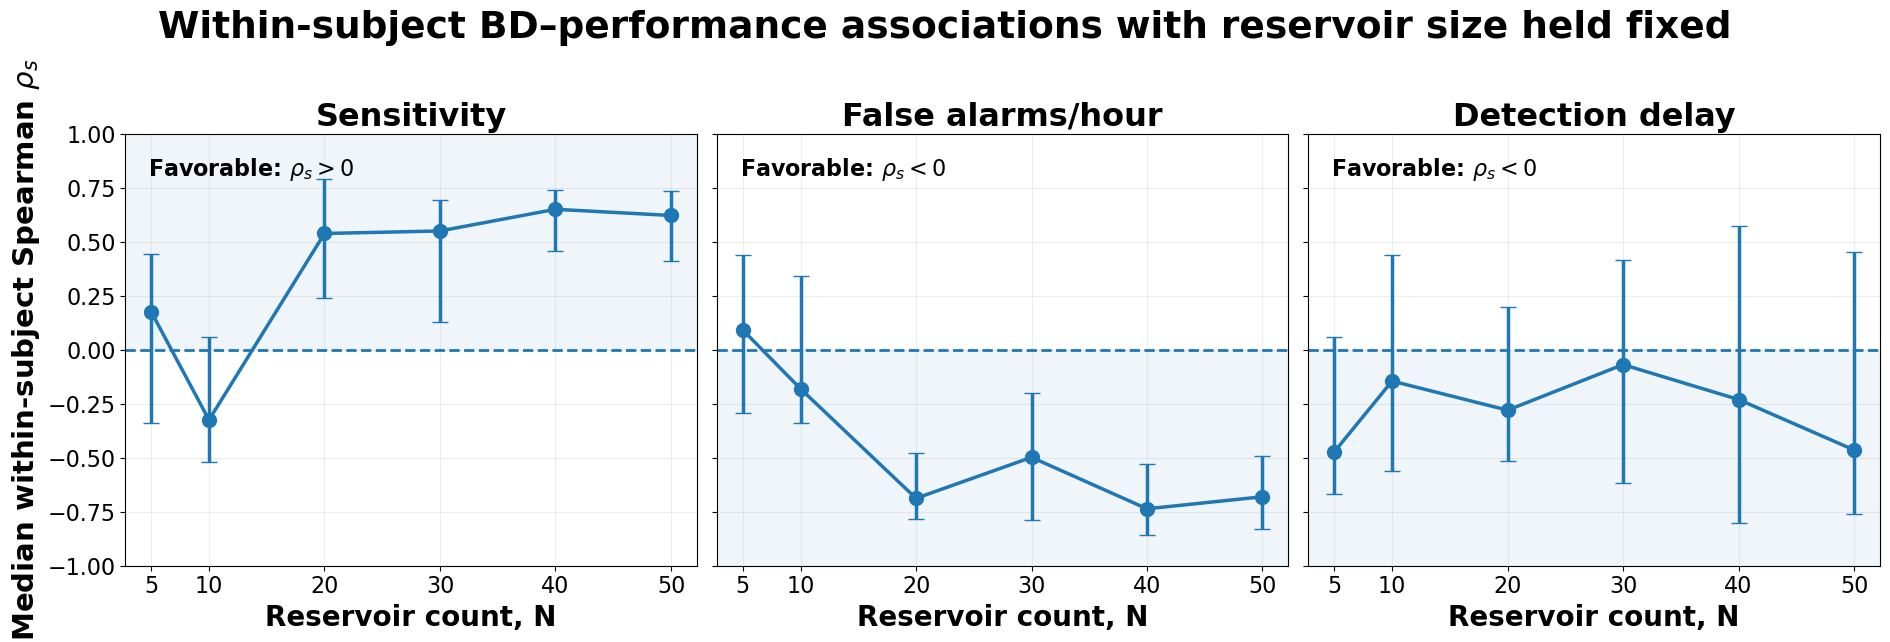

In [18]:
# ============================================================
# Median within-subject BD-performance correlation vs N
# ============================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 6.5),
    sharey=True,
)

for ax, metric_name in zip(
    axes,
    ["Sensitivity", "False alarms/hour", "Detection delay"]
):

    d = (
        fixedN_summary[
            fixedN_summary["metric"] == metric_name
        ]
        .sort_values("N")
        .copy()
    )

    ax.axhline(
        0,
        linestyle="--",
        linewidth=2,
    )

    # Favorable region
    if metric_name == "Sensitivity":
        ax.axhspan(
            0, 1,
            alpha=0.07,
        )
        direction = r"Favorable: $\rho_s > 0$"
    else:
        ax.axhspan(
            -1, 0,
            alpha=0.07,
        )
        direction = r"Favorable: $\rho_s < 0$"

    # Median and IQR
    yerr = np.vstack([
        d["median_rho"] - d["q25"],
        d["q75"] - d["median_rho"],
    ])

    ax.errorbar(
        d["N"],
        d["median_rho"],
        yerr=yerr,
        marker="o",
        markersize=10,
        linewidth=2.5,
        capsize=6,
    )

    ax.set_title(
        metric_name,
        fontsize=23,
        fontweight="bold",
    )

    ax.text(
        0.04,
        0.95,
        direction,
        transform=ax.transAxes,
        va="top",
        fontsize=16,
        fontweight="bold",
    )

    ax.set_xlabel(
        "Reservoir count, N",
        fontsize=20,
        fontweight="bold",
    )

    ax.set_xticks(N_VALUES)

    ax.tick_params(
        axis="both",
        labelsize=16,
    )

    ax.set_ylim(-1, 1)

    ax.grid(
        alpha=0.22,
    )

axes[0].set_ylabel(
    r"Median within-subject Spearman $\rho_s$",
    fontsize=21,
    fontweight="bold",
)

fig.suptitle(
    "Within-subject BD–performance associations with reservoir size held fixed",
    fontsize=27,
    fontweight="bold",
)

plt.tight_layout(
    rect=[0, 0, 1, 0.94]
)

plt.savefig(
    ANALYSIS_OUT /
    "BD_fixed_N_performance_associations.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## BD entropy across Rössler regimes and reservoir sizes


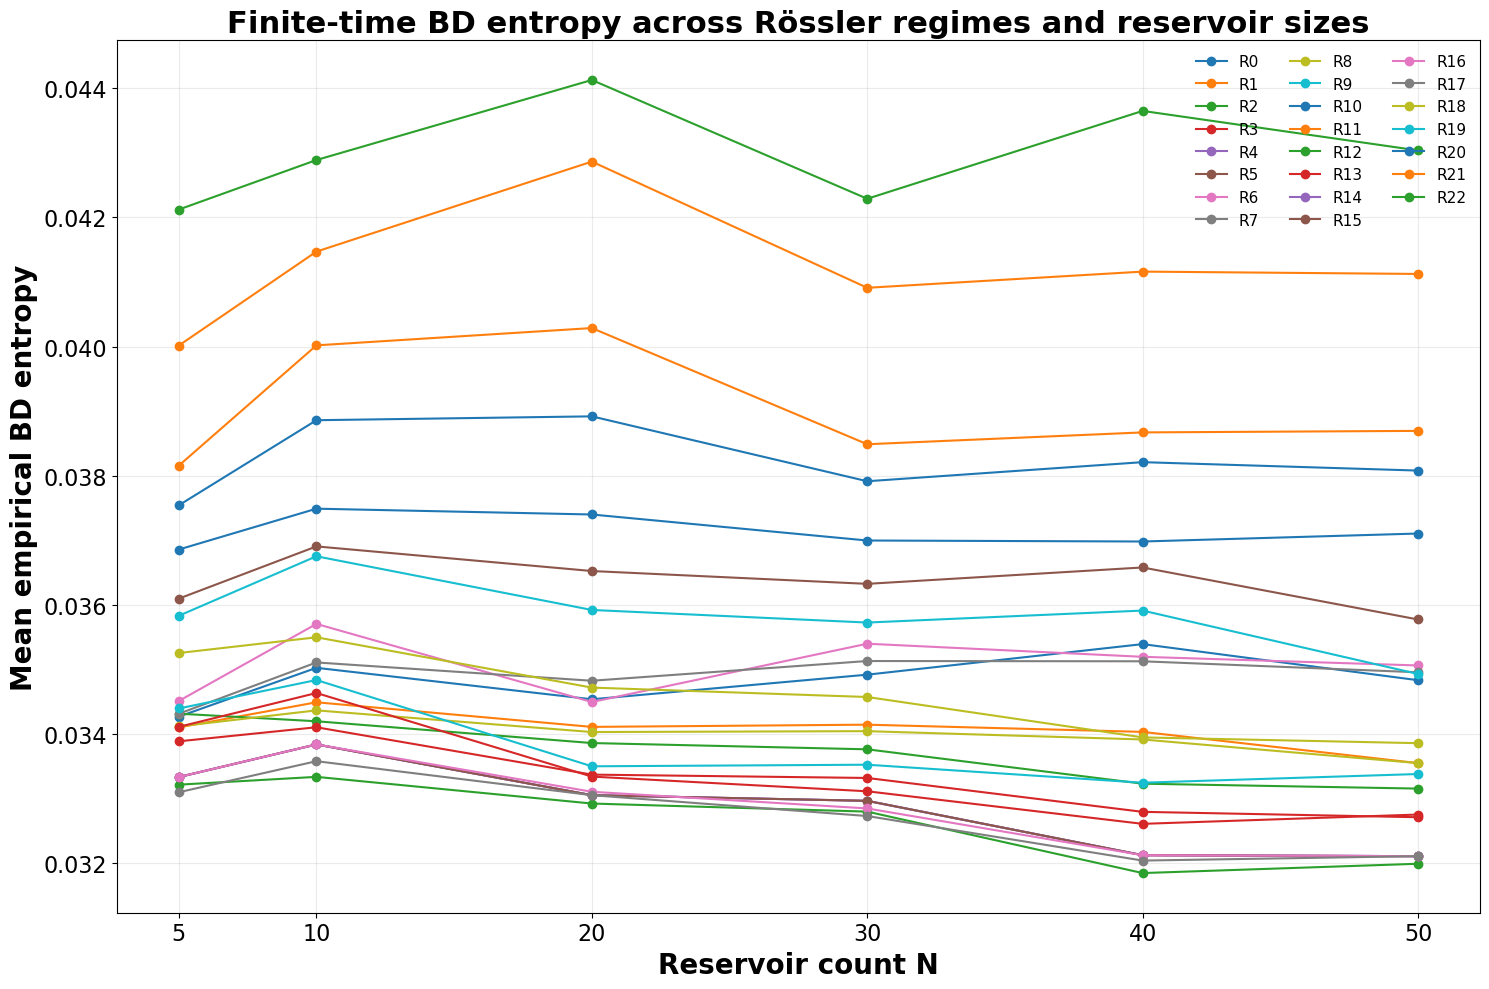

In [19]:
regime_N_bd = (
    subject_config_pooled
    .groupby(["regime_id", "N"], as_index=False)
    .agg(
        mean_bd=("bd_entropy_mean", "mean"),
        sd_bd=("bd_entropy_mean", "std"),
        n_subjects=("subject_id", "nunique"),
    )
)

plt.figure(figsize=(15, 10))
for regime_id, g in regime_N_bd.groupby("regime_id"):
    g = g.sort_values("N")
    plt.plot(g["N"], g["mean_bd"], marker="o", linewidth=1.5, label=f"R{regime_id}")

plt.xlabel("Reservoir count N", fontsize=20, fontweight="bold")
plt.ylabel("Mean empirical BD entropy", fontsize=20, fontweight="bold")
plt.title("Finite-time BD entropy across Rössler regimes and reservoir sizes", fontsize=22, fontweight="bold")
plt.xticks(N_VALUES, fontsize=16)
plt.yticks(fontsize=16)
plt.legend(ncol=3, fontsize=11, frameon=False)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [20]:
import numpy as np
import pandas as pd

df = results.copy() if "results" in globals() else raw.copy()
n_col = "N" if "N" in df.columns else "num_reservoirs"

primary = df.loc[
    df["regime_id"].eq(4)
    & df[n_col].eq(10)
    & np.isclose(df["persistence_seconds"], 3.0)
].copy()

if primary.duplicated(["patient", "res_seed"]).any():
    raise ValueError("Duplicate patient/seed rows: check before summarizing.")

case = primary.groupby("patient").agg(
    seeds=("res_seed", "nunique"),
    seizures_min=("n_seizures", "min"),
    seizures_max=("n_seizures", "max"),
    hours_min=("clean_interictal_hours", "min"),
    hours_max=("clean_interictal_hours", "max"),
    sensitivity=("seizure_sensitivity", "mean"),
    far=("false_alarms_per_hour", "mean"),
    delay=("mean_detection_delay_seconds", "mean"),
)

print("CASE RESULTS")
print(case.to_string())

print("\nMISSING CASES")
expected = {f"chb{i:02d}" for i in range(1, 25)}
print(sorted(expected - set(case.index)))

print("\nCASE-LEVEL SUMMARIES")
for col in ["sensitivity", "far", "delay"]:
    x = case[col].dropna()
    print(
        col,
        "cases:", len(x),
        "mean:", x.mean(),
        "median:", x.median(),
        "range:", (x.min(), x.max()),
    )

same_exposure = (
    case["seizures_min"].eq(case["seizures_max"]).all()
    and np.allclose(case["hours_min"], case["hours_max"])
)
if same_exposure:
    print("\nSeizures, counted once per case:",
          case["seizures_min"].sum())
    print("Interictal hours, counted once per case:",
          case["hours_min"].sum())
else:
    print("\nExposure differs across seeds; inspect before reporting totals.")

print("\nSOURCE FOLDERS")
for col in ["run_dir", "source_file"]:
    if col in primary.columns:
        print(primary[col].head().to_string(index=False))

CASE RESULTS
         seeds  seizures_min  seizures_max  hours_min  hours_max  sensitivity        far      delay
patient                                                                                            
chb01        5             7             7   8.739722   8.739722     0.000000   0.686521        NaN
chb02        5             3             3   8.000000   8.000000     0.533333  11.375000  21.166667
chb03        5             7             7   8.000000   8.000000     0.942857   8.900000  10.738095
chb04        5             4             4  39.459722  39.459722     0.050000  11.393897  23.000000
chb05        5             5             5   8.000000   8.000000     0.880000  12.400000  14.350000
chb06        5            10            10  23.451944  23.451944     0.060000   5.679700  26.500000
chb07        5             3             3  20.778333  20.778333     0.533333  29.001364  10.566667
chb08        5             5             5   4.000000   4.000000     0.600000  16.00000

In [21]:
print(corr_summary.to_string(index=False))
print(fixedN_summary.to_string(index=False))

           metric  n_subjects  median_rho       q25       q75  n_positive  n_negative  n_zero  n_favorable  favorable_fraction  wilcoxon_stat  wilcoxon_p
      Sensitivity          21    0.123431  0.019531  0.374574          16           5       0           16            0.761905           58.0    0.045993
False alarms/hour          23   -0.269706 -0.450188 -0.075532           5          18       0           18            0.782609           47.0    0.004339
  Detection delay          21   -0.104318 -0.377442  0.155545           8          13       0           13            0.619048           83.0    0.272210
 N            metric  n_subjects  median_rho       q25       q75  n_favorable  favorable_fraction  wilcoxon_stat  wilcoxon_p
 5       Sensitivity          15    0.176775 -0.336971  0.446355            9            0.600000           49.0    0.561401
 5 False alarms/hour          23    0.093068 -0.290268  0.439226            9            0.391304          113.0    0.463381
 5   Dete